# Day 47 — Activation and loss functions

Instructor: Srinivasa Sai Chava  
Audience: first-year undergraduates  
Time: about 90 minutes, including live code and questions

Day 46 built z = w·x + b and used a hard step. Today we answer two questions: What should a neuron output? How should we score the difference from the correct target? The first is an activation; the second is a loss.

Learning goals: evaluate and sketch common activations, choose outputs for four target types, calculate MSE, MAE and cross entropy, and distinguish loss from accuracy. Gradient-based weight updates come next lesson.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit, logsumexp

np.set_printoptions(precision=4, suppress=True)

def step(z):
    return (np.asarray(z) >= 0).astype(int)

def sigmoid(z):
    return expit(z)

def relu(z):
    return np.maximum(0, z)

def leaky_relu(z, alpha=.01):
    z = np.asarray(z)
    return np.where(z >= 0, z, alpha*z)

def softmax(logits):
    logits = np.asarray(logits, dtype=float)
    shifted = logits - np.max(logits, axis=-1, keepdims=True)
    exps = np.exp(shifted)
    return exps / np.sum(exps, axis=-1, keepdims=True)

def bce_from_logits(z,y):
    return np.logaddexp(0,z) - np.asarray(y)*np.asarray(z)

def ce_from_logits(logits,true_index):
    logits=np.asarray(logits,dtype=float)
    return logsumexp(logits) - logits[true_index]

## 1. From score to output (10 min)

An activation g takes the weighted score z and produces a=g(z). During supervised training, a loss L(a,y) compares that prediction with a known target y. Both functions are chosen with the task in mind.

Why nonlinearity? A stack of purely linear layers collapses into one linear transformation. Nonlinear hidden activations let connected neurons represent boundaries that one straight line cannot.

Pause and compute the Day 46 score for x=[1,1], w=[.8,.6], b=-1.

In [2]:
x=np.array([1.,1.]); w=np.array([.8,.6]); b=-1.
z=float(x@w+b)
print("z:",z,"step:",step(z),"sigmoid:",sigmoid(z))
assert np.isclose(z,.4)

z: 0.3999999999999999 step: 1 sigmoid: 0.598687660112452


## 2. Step, sigmoid, tanh (15 min)

- Step: 1 if z≥0, otherwise 0. This is a hard decision. It has zero slope away from the jump and no ordinary derivative at the jump, so it is awkward for gradient training.
- Sigmoid: σ(z)=1/(1+e⁻ᶻ). Its output lies strictly between 0 and 1; σ(0)=.5. Common for one binary output. A sigmoid value alone does not guarantee calibrated probabilities.
- Tanh: output lies strictly between -1 and 1, centered at zero. It also flattens for large absolute scores.

Sigmoid and tanh saturate at extreme values, so their slopes become small. This can weaken gradient signals through many layers. The hard step, sigmoid and tanh return different kinds of output even when fed the same z.

step [0 0 1 1 1]
sigmoid [0.018  0.1192 0.5    0.8808 0.982 ]
tanh [-0.9993 -0.964   0.      0.964   0.9993]


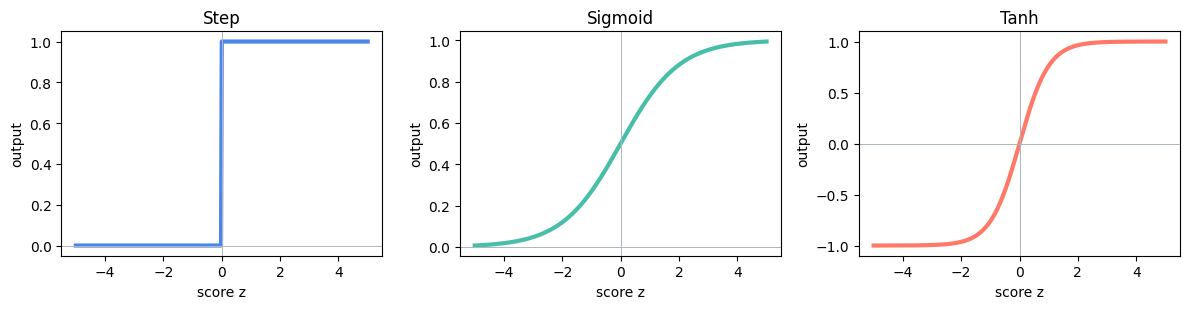

In [3]:
scores=np.array([-4.,-2.,0.,2.,4.])
for name,vals in [("step",step(scores)),("sigmoid",sigmoid(scores)),("tanh",np.tanh(scores))]:
    print(name,np.round(vals,4))
assert np.isclose(sigmoid(0),.5)
grid=np.linspace(-5,5,401)
fig,axes=plt.subplots(1,3,figsize=(12,3.2))
for a,name,values,color in zip(axes,["Step","Sigmoid","Tanh"],
    [step(grid),sigmoid(grid),np.tanh(grid)],["#4c85e9","#47bfa8","#ff7868"]):
    a.plot(grid,values,color=color,lw=3)
    a.axhline(0,color="#abb6c2",lw=.7);a.axvline(0,color="#abb6c2",lw=.7)
    a.set(xlabel="score z",ylabel="output",title=name)
fig.tight_layout();plt.show()

For z=.4: step gives 1, sigmoid about .599, tanh about .380. The first is a class label; the other two are continuous values with different ranges.

## 3. ReLU and Leaky ReLU (10 min)

ReLU(z)=max(0,z) keeps positive scores and sets negative ones to zero. It is common in hidden layers. Its slope is 0 for negative scores and 1 for positive scores; libraries select a subgradient at exactly zero. A unit that remains on the negative side can become a dead ReLU.

LeakyReLU(z)=max(αz,z) uses a small slope α on the negative side. α=.01 is an illustrative value, not a universal best setting.

ReLU: [0. 0. 0. 1. 3.]
Leaky: [-0.02  -0.005  0.     1.     3.   ]


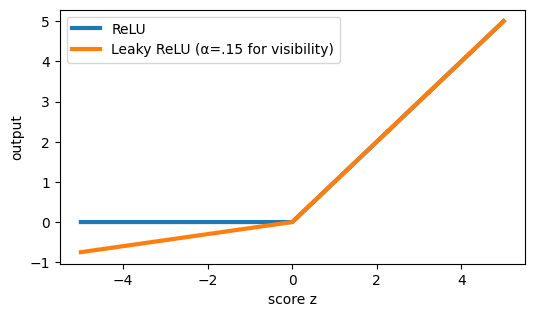

In [4]:
scores=np.array([-2.,-.5,0.,1.,3.])
print("ReLU:",relu(scores));print("Leaky:",leaky_relu(scores))
assert np.allclose(relu(scores),[0,0,0,1,3])
fig,ax=plt.subplots(figsize=(6,3.3))
ax.plot(grid,relu(grid),lw=3,label="ReLU")
ax.plot(grid,leaky_relu(grid,.15),lw=3,label="Leaky ReLU (α=.15 for visibility)")
ax.set(xlabel="score z",ylabel="output");ax.legend();plt.show()

## 4. Softmax and output choices (15 min)

For exactly one of K mutually exclusive classes, softmax converts K logits to positive values summing to 1:
pᵢ = exp(zᵢ) / Σⱼ exp(zⱼ).

Subtract the maximum logit before exponentiating. This prevents overflow and leaves the probabilities unchanged. For independent labels, use one sigmoid per label. A photo can contain both a dog and a tree, so those labels must not compete in a softmax.

| Target | Conceptual output | Example |
|---|---|---|
| Number | Linear/identity | Temperature |
| One yes/no label | Sigmoid | Spam? |
| Exactly one of K | Softmax | Cat, dog or bird |
| Several labels | Sigmoid per label | Dog and tree tags |

In [5]:
logits=np.array([2.,1.,0.])
probs=softmax(logits)
print(probs,"sum:",probs.sum(),"after shift:",softmax(logits+1000))
assert np.allclose(probs,[.66524096,.24472847,.09003057])
assert np.allclose(probs,softmax(logits+1000))

[0.6652 0.2447 0.09  ] sum: 0.9999999999999999 after shift: [0.6652 0.2447 0.09  ]


## 5. Loss and regression (10 min)

Loss is a numerical penalty comparing prediction with target. Training commonly minimizes mean loss over a batch. Accuracy counts thresholded correct labels; two predictions with equal accuracy can have different losses.

For numerical targets:
- MSE = mean((y-ŷ)²). Squaring emphasizes large misses.
- MAE = mean(|y-ŷ|). The penalty grows linearly with error size.

Targets [3,3] and predictions [2.5,5] give squared errors [.25,4] and absolute errors [.5,2]. Thus MSE=2.125 and MAE=1.25. MAE has a corner at zero error, where a subgradient is selected.

In [6]:
y=np.array([3.,3.]);pred=np.array([2.5,5.])
mse=np.mean((y-pred)**2);mae=np.mean(np.abs(y-pred))
print("MSE",mse,"MAE",mae)
assert np.isclose(mse,2.125) and np.isclose(mae,1.25)

MSE 2.125 MAE 1.25


## 6. Binary cross entropy (10 min)

For binary target y∈{0,1} and probability p between 0 and 1:
L = -[y log(p) + (1-y) log(1-p)].

If y=1, L=-log(p). If y=0, L=-log(1-p). Natural logarithms are used. A confidently wrong probability gets a large penalty. For y=1, p=.8 gives .223, while p=.1 gives 2.303.

A naive log on a probability that rounds to 0 is unsafe. A stable implementation works directly from the logit z: softplus(z)-yz. In PyTorch, BCEWithLogitsLoss expects the raw logit. Do not apply sigmoid first.

In [7]:
for y,p in [(1,.8),(1,.1),(0,.8)]:
    z=np.log(p/(1-p))
    print(y,p,float(bce_from_logits(z,y)))
print("large wrong logit:",bce_from_logits(-1000.,1))
assert np.isclose(bce_from_logits(np.log(.8/.2),1),-np.log(.8))

1 0.8 0.2231435513142097
1 0.1 2.3025850929940455
0 0.8 1.6094379124341005
large wrong logit: 1000.0


## 7. Multiclass cross entropy (5 min)

For one true class in a softmax output, multiclass cross entropy is -log(p_true). With logits [2,1,0], the probabilities are approximately [.665,.245,.090]. True cat (index 0) costs .408; true bird (index 2) costs 2.408.

PyTorch CrossEntropyLoss expects logits and the class index. It computes the stable log-softmax internally; do not softmax before that routine.

In [8]:
logits=np.array([2.,1.,0.])
for target in [0,2]:
    print("class",target,"loss",ce_from_logits(logits,target))
assert np.isclose(ce_from_logits(logits,0),-np.log(softmax(logits)[0]))

class 0 loss 0.4076059644443806
class 2 loss 2.4076059644443806


## 8. One full example (10 min)

Back to Day 46: x=[1,1], w=[.8,.6], b=-1 gives z=.4. Sigmoid gives p≈.599. For correct target y=1, BCE=-log(.599)≈.513. The hard class label is correct at threshold .5, but its confidence is modest. Loss sees information that accuracy discards.

In [9]:
x=np.array([1.,1.]);w=np.array([.8,.6]);b=-1.
z=float(x@w+b);p=float(sigmoid(z));y=1
print(f"z={z:.3f}, p={p:.3f}, label={int(p>=.5)}, BCE={float(bce_from_logits(z,y)):.3f}")
assert np.isclose(p,.59868766)

z=0.400, p=0.599, label=1, BCE=0.513


### Matching checklist

| Task | Conceptual output | Loss |
|---|---|---|
| Regression | Linear | MSE or MAE |
| Binary | Sigmoid | Binary cross entropy |
| Mutually exclusive multiclass | Softmax | Multiclass cross entropy |
| Independent multilabel | Sigmoid per label | Binary cross entropy per label |

The conceptual output column describes probabilities for interpretation. PyTorch's BCEWithLogitsLoss and CrossEntropyLoss take raw logits when training.

## Exit ticket (5 min)

1. Why can accuracy tie while BCE differs?
2. What output and loss fit three mutually exclusive classes?
3. Why is a step activation awkward for gradient descent?

Next: the forward pass, derivatives and gradient-based weight changes. Work through the 12 practice questions separately.

### Primary references

- PyTorch activations: https://docs.pytorch.org/docs/stable/nn.html
- PyTorch BCEWithLogitsLoss: https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html
- PyTorch CrossEntropyLoss: https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
- PyTorch MSELoss: https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html
- Goodfellow et al., Deep Learning, Chapter 6: https://www.deeplearningbook.org/contents/mlp.html

The notebook uses NumPy, SciPy and Matplotlib in a standard Colab runtime.